# U-Net baseline: train, predict, and evaluate

Run the cells in order. The default **`MODE = "pretrained"`** evaluates the
published `Checkpoint_Data/unet_rgb5.hdf5` weights. Set **`MODE = "train"`** to
train a fresh model, or **`MODE = "checkpoint"`** to evaluate your own saved weights.
Training and checkpoint evaluation always use the same architecture and five
foreground channels: **RO, FV, HD, RI, WR**. Water, plants, and sea-floor produce
all-zero foreground targets. This is the upstream five-category task.

The relevant Python code is included directly in the cells, adapted from
[xahidbuffon/SUIM](https://github.com/xahidbuffon/SUIM/tree/59f7cb0d4d13289434ad6e3ab162ab7a5dcc5c84):

| Source | Code used here |
| --- | --- |
| `models/unet.py` | `UNet0` architecture, including its three-filter layer before the output |
| `train_unet.py` | Adam, binary cross-entropy, batch size, augmentation settings, checkpointing |
| `utils/data_utils.py` | RGB scaling, channel thresholding, five foreground targets, shared augmentation |
| `test_unet.py` | Weight loading, image scaling, prediction thresholding, per-class BMP outputs |
| `get_f1_iou.py` | Per-image evaluation, exclusion of empty ground truths, per-category averages |
| `utils/measure_utils.py` | Binary IoU and boundary F-score |

**Adaptations:** current TensorFlow/Keras APIs; pairing by stem; reviewed mask
crops; one shared augmentation decision with nearest-neighbor mask interpolation;
a saved split that keeps byte-identical images together; checkpoint selection by
validation loss; and one pass through the training partition per epoch instead
of the upstream hardcoded 5,000 batches. These training results are an adapted
baseline, not an exact reproduction of the paper's training run. Published-weight
inference retains the original architecture and five-category evaluation rule.
The original dataset is unchanged. Local test scripts use separate output
folders for each model.

## Environment

Use a separate Python 3.12 environment. From the project root in PowerShell:

```powershell
python -m venv .venv-unet
.\.venv-unet\Scripts\python.exe -m pip install -r requirements-unet.txt
.\.venv-unet\Scripts\python.exe -m ipykernel install --sys-prefix --name suim-unet --display-name "Python (SUIM U-Net)"
```

Select **`.venv-unet/Scripts/python.exe`** as this notebook's kernel in VS Code.
For a standalone copy, install `tensorflow==2.20.0`, `numpy>=1.26,<2.3`, `Pillow`,
`scipy`, `pandas`, `matplotlib`, and `ipykernel` in its environment.
[TensorFlow installation](https://www.tensorflow.org/install/pip) documents CPU
support on native Windows; current NVIDIA GPU training requires a supported
Linux/WSL2 setup. The imports below print the detected devices.

In [1]:
import csv
import hashlib
import json
import math
import os
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_dilation
from IPython.display import display
try:
    import tensorflow as tf
except ImportError as error:
    raise ImportError('Select the U-Net kernel and install requirements-unet.txt first.') from error
from tensorflow import keras
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Conv2D, UpSampling2D, MaxPooling2D, concatenate, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0 | Keras: 3.15.1
GPU devices: []


## Configuration

`ROOT` is the dataset root containing `train_val/` and `TEST/`. It is detected
from the current directory or its parents; replace it with an explicit `Path`
when the dataset is elsewhere. The training directory defaults to our
`cleaned_suim/train_val/`, falling back to original `train_val/` with the same
37 reviewed crops applied in memory.

Keep `MAX_TEST_IMAGES = None` for the full benchmark. Setting a number makes a
partial smoke run and is recorded in the output. `MODE = "train"` starts the
configured training run; all other modes skip training. Set `EPOCHS` deliberately
before choosing training. Outputs use fixed folders for each model:
`data/test/output/unet/` for predictions, split, metric tables, summary, and preview;
`ckpt/` for training weights, history, and loss plot. Rerunning overwrites
previous U-Net outputs; other models use their own output folders. `CUSTOM_WEIGHTS` defaults to `ckpt/unet_rgb.weights.h5`.

In [2]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'train_val/images').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Set ROOT to the SUIM folder containing train_val/ and TEST/.')
ROOT = ROOT.resolve()
MODE = 'pretrained'  # 'pretrained', 'train', or 'checkpoint'
TRAIN_DIR = ROOT / 'cleaned_suim/train_val'
if not TRAIN_DIR.is_dir():
    TRAIN_DIR = ROOT / 'train_val'
TEST_DIR = ROOT / 'TEST'
PRETRAINED_WEIGHTS = ROOT / 'Checkpoint_Data/unet_rgb5.hdf5'
OUTPUT_DIR = ROOT / 'data/test/output/unet'
CKPT_DIR = ROOT / 'ckpt'
CUSTOM_WEIGHTS = CKPT_DIR / 'unet_rgb.weights.h5'

WIDTH, HEIGHT = 320, 240
BATCH_SIZE = 2
INFERENCE_BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 1e-4
VALIDATION_FRACTION = 0.2
SEED = 42
PREDICTION_THRESHOLD = 0.5
MAX_TEST_IMAGES = None
USE_AUGMENTATION = True
CLASSES = ['RO', 'FV', 'HD', 'RI', 'WR']  # Exact upstream channel order.
AUGMENTATION = dict(rotation_range=0.2, width_shift_range=0.05,
                    height_shift_range=0.05, shear_range=0.05, zoom_range=0.05,
                    horizontal_flip=True, fill_mode='nearest')

if MODE not in {'pretrained', 'train', 'checkpoint'}:
    raise ValueError('Choose MODE = pretrained, train, or checkpoint')
if WIDTH <= 0 or HEIGHT <= 0 or WIDTH % 16 or HEIGHT % 16:
    raise ValueError('WIDTH and HEIGHT must be positive multiples of 16')
if not 0 < VALIDATION_FRACTION < 1:
    raise ValueError('VALIDATION_FRACTION must be between 0 and 1')
if MAX_TEST_IMAGES is not None and (not isinstance(MAX_TEST_IMAGES, int) or MAX_TEST_IMAGES < 1):
    raise ValueError('MAX_TEST_IMAGES must be None or a positive integer')
keras.utils.set_random_seed(SEED)
print('Mode:', MODE, '| Training:', TRAIN_DIR, '| Test:', TEST_DIR)
print('Output directory (overwritten on each run):', OUTPUT_DIR)
print('Training checkpoint directory:', CKPT_DIR)

Mode: pretrained | Training: C:\Users\darre\OneDrive\Desktop\SUIM\cleaned_suim\train_val | Test: C:\Users\darre\OneDrive\Desktop\SUIM\TEST
Output directory (overwritten on each run): C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\unet
Training checkpoint directory: C:\Users\darre\OneDrive\Desktop\SUIM\ckpt


## Data pairing, label conversion, and split

The target conversion below is a vectorized adaptation of
`getRobotFishHumanReefWrecks` and `processSUIMDataRFHW`. As upstream does, it
thresholds RGB channels at 127.5; this **chooses the upstream threshold policy**
for noncanonical colors. It does not use the cleaner's optional class-ID masks.

Image-file SHA-256 groups are assigned wholly to training or validation. Both
conflicting annotations are retained in one partition until manually reviewed.
The split is seeded, saved, and is not class-stratified. TEST is used for final
prediction/evaluation only and never to choose checkpoints or tune parameters.

In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def index_files(folder, extensions):
    files = {}
    for path in sorted(Path(folder).iterdir()):
        if path.is_file() and path.suffix.lower() in extensions:
            if path.stem in files:
                raise ValueError(f'Ambiguous stem: {folder / path.stem}')
            files[path.stem] = path
    return files


# Accepted original dimensions, embedded for reading original or cleaned data.
REVIEWED_CROPS = {
    'f_r_1058_': ((590, 375), (590, 430)),
    'f_r_1068_': ((590, 375), (590, 430)),
    'f_r_1069_': ((590, 375), (590, 430)),
    'f_r_1070_': ((590, 375), (590, 430)),
    'f_r_1133_': ((590, 375), (590, 430)),
    'f_r_1142_': ((590, 375), (590, 430)),
    'f_r_1151_': ((590, 375), (590, 430)),
    'f_r_1154_': ((590, 375), (590, 430)),
    'f_r_1214_': ((590, 375), (590, 430)),
    'f_r_1233_': ((590, 375), (590, 430)),
    'f_r_1259_': ((910, 435), (910, 490)),
    'f_r_1289_': ((590, 375), (590, 430)),
    'f_r_1290_': ((910, 435), (910, 490)),
    'f_r_1302_': ((590, 375), (590, 430)),
    'f_r_1318_': ((590, 375), (590, 430)),
    'f_r_1394_': ((910, 435), (910, 490)),
    'f_r_1424_': ((590, 375), (590, 430)),
    'f_r_1491_': ((590, 375), (590, 430)),
    'f_r_1515_': ((590, 375), (590, 430)),
    'f_r_1570_': ((910, 435), (910, 490)),
    'f_r_1779_': ((590, 375), (590, 430)),
    'f_r_1812_': ((910, 435), (910, 490)),
    'f_r_1816_': ((590, 375), (590, 430)),
    'f_r_1866_': ((590, 375), (590, 430)),
    'f_r_1879_': ((590, 375), (590, 430)),
    'f_r_401_': ((910, 435), (910, 490)),
    'f_r_829_': ((590, 375), (590, 430)),
    'f_r_921_': ((590, 375), (590, 430)),
    'f_r_934_': ((590, 375), (590, 430)),
    'f_r_968_': ((590, 375), (590, 430)),
    'f_r_991_': ((590, 375), (590, 430)),
    'w_r_1_': ((590, 375), (590, 430)),
    'w_r_24_': ((590, 375), (590, 430)),
    'w_r_25_': ((590, 375), (590, 430)),
    'w_r_27_': ((590, 375), (590, 430)),
    'w_r_47_': ((590, 375), (590, 430)),
    'w_r_7_': ((590, 375), (590, 430)),
}


def read_rgb_pair(stem, images, masks, size):
    with Image.open(images[stem]) as source:
        image = source.convert('RGB')
    with Image.open(masks[stem]) as source:
        mask = source.convert('RGB')
    reviewed = REVIEWED_CROPS.get(stem)
    if reviewed is not None and image.size != reviewed[0]:
        raise ValueError(f'{stem}: reviewed image dimensions changed')
    if image.size != mask.size:
        if reviewed != (image.size, mask.size):
            raise ValueError(f'{stem}: unreviewed mismatch {image.size} / {mask.size}')
        mask = mask.crop((0, 0, image.width, image.height))
    # Upstream directory loader uses nearest-neighbor initial resizing.
    image = image.resize(size, Image.Resampling.NEAREST)
    mask = mask.resize(size, Image.Resampling.NEAREST)
    return np.asarray(image, dtype=np.float32), np.asarray(mask, dtype=np.float32)


def getRobotFishHumanReefWrecks(mask):
    colors = np.array([(1, 0, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1)])
    return np.all(np.asarray(mask)[..., None, :] == colors, axis=-1).astype(np.float32)


def processSUIMDataRFHW(image, mask):
    return np.asarray(image, dtype=np.float32) / 255.0, getRobotFishHumanReefWrecks(np.asarray(mask) > 127.5)


def grouped_split(images, validation_fraction, seed):
    groups = {}
    for stem, path in images.items():
        groups.setdefault(file_sha256(path), []).append(stem)
    if len(groups) < 2:
        raise ValueError('At least two unique image groups are needed for a split')
    hashes = np.array(sorted(groups))
    np.random.default_rng(seed).shuffle(hashes)
    n_validation = min(len(hashes) - 1, max(1, round(len(hashes) * validation_fraction)))
    validation_hashes = set(hashes[:n_validation])
    rows = [{'stem': stem, 'image_sha256': digest,
             'partition': 'validation' if digest in validation_hashes else 'train'}
            for digest, stems in sorted(groups.items()) for stem in stems]
    return pd.DataFrame(rows).sort_values('stem').reset_index(drop=True)

In [4]:
train_images = index_files(TRAIN_DIR / 'images', {'.jpg', '.jpeg', '.png'})
train_masks = index_files(TRAIN_DIR / 'masks', {'.bmp', '.png'})
if not train_images or train_images.keys() != train_masks.keys():
    raise ValueError('Training images and RGB masks must pair exactly by stem')
split = grouped_split(train_images, VALIDATION_FRACTION, SEED)
assert split.groupby('image_sha256').partition.nunique().max() == 1
train_stems = split.loc[split.partition == 'train', 'stem'].tolist()
validation_stems = split.loc[split.partition == 'validation', 'stem'].tolist()

test_images = index_files(TEST_DIR / 'images', {'.jpg', '.jpeg', '.png'})
if not test_images:
    raise ValueError('No TEST images found')
ground_truth = {symbol: index_files(TEST_DIR / 'masks' / symbol, {'.bmp', '.png'}) for symbol in CLASSES}
for symbol, masks in ground_truth.items():
    if masks.keys() != test_images.keys():
        raise ValueError(f'TEST {symbol} masks do not pair exactly with TEST images')
selected_test_stems = sorted(test_images)
if MAX_TEST_IMAGES is not None:
    selected_test_stems = selected_test_stems[:MAX_TEST_IMAGES]
print(f'{len(train_stems)} training + {len(validation_stems)} validation pairs')
print(f'{len(selected_test_stems)}/{len(test_images)} TEST images selected')
print('Repeated-image groups:', int((split.groupby('image_sha256').size() > 1).sum()))

1220 training + 305 validation pairs
110/110 TEST images selected
Repeated-image groups: 9


## Paired batch loader

This replaces the separate directory iterators and Python 2 `it.izip` in
`utils/data_utils.py`. Augmentation ranges come from `train_unet.py`. A single
transform is applied to both members, using interpolation order 1 for images
and 0 for RGB masks. Validation data is neither shuffled nor augmented.

In [5]:
class SUIMBatches(keras.utils.PyDataset):
    def __init__(self, stems, images, masks, batch_size, size, *, augment=False, shuffle=False):
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=1)
        if not stems or batch_size < 1:
            raise ValueError('A nonempty stem list and positive batch size are required')
        self.stems, self.images, self.masks = tuple(stems), images, masks
        self.batch_size, self.size = batch_size, size
        self.augment, self.shuffle, self.epoch = augment, shuffle, 0
        self.order = np.arange(len(self.stems))
        self.image_aug = ImageDataGenerator(**AUGMENTATION, interpolation_order=1)
        self.mask_aug = ImageDataGenerator(**AUGMENTATION, interpolation_order=0)
        if shuffle:
            np.random.default_rng(SEED).shuffle(self.order)

    def __len__(self):
        return math.ceil(len(self.stems) / self.batch_size)

    def __getitem__(self, index):
        if index < 0 or index >= len(self):
            raise IndexError(index)
        xs, ys = [], []
        for position in self.order[index * self.batch_size:(index + 1) * self.batch_size]:
            image, mask = read_rgb_pair(self.stems[position], self.images, self.masks, self.size)
            if self.augment:
                params = self.image_aug.get_random_transform(image.shape, seed=SEED + self.epoch * len(self.stems) + int(position))
                image = self.image_aug.apply_transform(image, params)
                mask = self.mask_aug.apply_transform(mask, params)
            image, target = processSUIMDataRFHW(image, mask)
            xs.append(image)
            ys.append(target)
        return np.stack(xs), np.stack(ys)

    def on_epoch_end(self):
        self.epoch += 1
        if self.shuffle:
            np.random.default_rng(SEED + self.epoch).shuffle(self.order)

## U-Net architecture from `models/unet.py`

The function body below is taken from the upstream `UNet0`. Changes are limited
to current imports, `Model(inputs=..., outputs=...)`, `Adam(learning_rate=...)`,
an explicit binary-accuracy metric, and moving its summary print to the next cell.
All convolution widths, kernels, skip connections, dropouts, and five sigmoid
outputs are preserved so the published checkpoint can load by topology.

In [6]:
def UNet0(input_size = (256, 256, 3), no_of_class = 3):
    inputs = Input(input_size)
    conv1 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(inputs)
    conv1 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool1)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)
    conv4 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool3)
    conv4 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
    drop4 = Dropout(0.5)(conv4)
    pool4 = MaxPooling2D(pool_size=(2, 2))(drop4)

    conv5 = Conv2D(1024, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool4)
    conv5 = Conv2D(1024, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
    drop5 = Dropout(0.5)(conv5)

    up6 = Conv2D(512, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(drop5))
    merge6 = concatenate([drop4,up6], axis = 3)
    conv6 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge6)
    conv6 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv6)

    up7 = Conv2D(256, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv6))
    merge7 = concatenate([conv3,up7], axis = 3)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge7)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv7)

    up8 = Conv2D(128, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv7))
    merge8 = concatenate([conv2,up8], axis = 3)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge8)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv8)

    up9 = Conv2D(64, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv8))
    merge9 = concatenate([conv1,up9], axis = 3)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge9)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv9)
    conv9 = Conv2D(3, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv9)
    conv10 = Conv2D(no_of_class, 3, padding = 'same', activation = 'sigmoid')(conv9)

    model = Model(inputs=inputs, outputs=conv10)
    model.compile(optimizer = Adam(learning_rate=LEARNING_RATE), loss = 'binary_crossentropy', metrics=['binary_accuracy'])    
    # Summary is displayed after selecting the checkpoint below.


    return model

In [7]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = UNet0(input_size=(HEIGHT, WIDTH, 3), no_of_class=len(CLASSES))
WEIGHTS_PATH = None
if MODE in {'pretrained', 'checkpoint'}:
    WEIGHTS_PATH = PRETRAINED_WEIGHTS if MODE == 'pretrained' else CUSTOM_WEIGHTS
    if not WEIGHTS_PATH.is_file():
        raise FileNotFoundError(f'Checkpoint not found: {WEIGHTS_PATH}')
    model.load_weights(str(WEIGHTS_PATH))  # Strict loading: no skipped mismatches.
    print('Loaded:', WEIGHTS_PATH)
else:
    print('Initialized fresh weights for training.')
model.summary()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
split.to_csv(OUTPUT_DIR / 'split.csv', index=False)
BEST_WEIGHTS = CKPT_DIR / 'unet_rgb.weights.h5'


Loaded: C:\Users\darre\OneDrive\Desktop\SUIM\Checkpoint_Data\unet_rgb5.hdf5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 240, 320,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 240, 320,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 240, 320,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 120, 160,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 120, 160,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 120, 160,  │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 60, 80,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 60, 80,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 60, 80,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 30, 40,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 30, 40,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 30, 40,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 30, 40,    │          0 │ conv2d_7[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 15, 20,    │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 15, 20,    │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 15, 20,    │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 15, 20,    │          0 │ conv2d_9[0][0]  

 Total params: 31,033,551 (118.38 MB)

 Trainable params: 31,033,551 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

## Train (only when `MODE = "train"`)

Adapted from `train_unet.py`: Adam at `1e-4`, batch size 2, binary cross-entropy,
and the original augmentation ranges. `model.fit` replaces `fit_generator`.
Each epoch visits the training partition once. The best **validation-loss**
weights are saved and reloaded before TEST prediction. TEST never selects weights.
Training outputs reuse `ckpt/`: `unet_rgb.weights.h5`,
`training_history.csv`, and `training_loss.png`. The `.weights.h5` suffix
follows current Keras weights-only saving; upstream used `unet_rgb.hdf5`.

In [8]:
if MODE == 'train':
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    training_batches = SUIMBatches(train_stems, train_images, train_masks, BATCH_SIZE, (WIDTH, HEIGHT),
                                  augment=USE_AUGMENTATION, shuffle=True)
    validation_batches = SUIMBatches(validation_stems, train_images, train_masks, BATCH_SIZE, (WIDTH, HEIGHT))
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(BEST_WEIGHTS), monitor='val_loss', save_best_only=True,
                                        save_weights_only=True, mode='min', verbose=1),
        keras.callbacks.CSVLogger(str(CKPT_DIR / 'training_history.csv')),
        keras.callbacks.TerminateOnNaN(),
    ]
    history = model.fit(training_batches, validation_data=validation_batches,
                        epochs=EPOCHS, callbacks=callbacks, shuffle=False)
    if not BEST_WEIGHTS.is_file():
        raise RuntimeError('Training did not produce a valid best checkpoint')
    model.load_weights(str(BEST_WEIGHTS))
    WEIGHTS_PATH = BEST_WEIGHTS
    history_table = pd.DataFrame(history.history)
    history_table[['loss', 'val_loss']].plot(title='U-Net binary cross-entropy', xlabel='Epoch')
    plt.tight_layout()
    plt.savefig(CKPT_DIR / 'training_loss.png', dpi=140)
    plt.show()
else:
    print('Training skipped. Set MODE = "train" in Configuration to train from scratch.')

Training skipped. Set MODE = "train" in Configuration to train from scratch.


## TEST predictions from `test_unet.py`

Use the selected weights, resize RGB inputs as in upstream testing (Pillow
bicubic), scale to `[0, 1]`, and threshold each channel independently at `> 0.5`.
Predictions are five binary BMP files per image, saved under
`data/test/output/unet/{RO,FV,HD,RI,WR}/`. This keeps the upstream
per-category layout inside a U-Net folder shared with local `test_unet.py`.
The code pairs files by stem and replaces the previous prediction masks
on each run, including masks left from a larger TEST selection.

In [9]:
def predict_and_save(model, image_paths, stems, output_dir, size, batch_size, threshold):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for symbol in CLASSES:
        class_dir = output_dir / symbol
        class_dir.mkdir(exist_ok=True)
        # Replace previous predictions, including masks outside a partial run.
        for previous in class_dir.iterdir():
            if previous.is_file() and previous.suffix.lower() in {'.bmp', '.png'}:
                previous.unlink()
    for start in range(0, len(stems), batch_size):
        selected = stems[start:start + batch_size]
        images = []
        for stem in selected:
            with Image.open(image_paths[stem]) as source:
                image = source.convert('RGB').resize(size, Image.Resampling.BICUBIC)
            images.append(np.asarray(image, dtype=np.float32) / 255.0)
        probabilities = model(np.stack(images), training=False).numpy()
        if probabilities.shape != (len(selected), size[1], size[0], len(CLASSES)):
            raise ValueError(f'Unexpected model output shape: {probabilities.shape}')
        if not np.isfinite(probabilities).all():
            raise ValueError('Non-finite predictions')
        binary = probabilities > threshold
        for index, stem in enumerate(selected):
            for channel, symbol in enumerate(CLASSES):
                Image.fromarray(binary[index, ..., channel].astype(np.uint8) * 255).save(output_dir / symbol / f'{stem}.bmp')
        if start == 0 or start + batch_size >= len(stems) or (start + batch_size) % 20 == 0:
            print(f'Predicted {min(start + batch_size, len(stems))}/{len(stems)} images')
    return output_dir

In [10]:
PREDICTION_DIR = predict_and_save(model, test_images, selected_test_stems, OUTPUT_DIR,
                                  (WIDTH, HEIGHT), INFERENCE_BATCH_SIZE, PREDICTION_THRESHOLD)
pd.DataFrame({'stem': selected_test_stems,
              'image_path': [str(test_images[s]) for s in selected_test_stems]}).to_csv(OUTPUT_DIR / 'test_images.csv', index=False)

Predicted 1/110 images
Predicted 20/110 images
Predicted 40/110 images
Predicted 60/110 images
Predicted 80/110 images
Predicted 100/110 images
Predicted 110/110 images


## Boundary F-score and IoU from the upstream evaluator

This ports `db_eval_boundary`, `seg2bmap`, and `IoU_bin` from
`utils/measure_utils.py`, plus the loop in `get_f1_iou.py`. The F-score is a
**boundary F-score**, not pixel Dice/F1. Boundary tolerance is the upstream
`0.008 * image diagonal`, rounded up. SciPy dilation uses the same disk footprint
in place of scikit-image. The unused boundary-map resizing branch is omitted.

As in upstream, each category's mean is over images **where that ground-truth
category is present**. False positives on absent-category images do not enter
that mean; their pixel counts are retained in the per-image report. We compute
all five categories, then report the macro mean of their means. This differs
from a global confusion-matrix IoU or an eight-class mIoU.

Evaluation mask resizing retains upstream bicubic + `>= 0.5` binarization.
This metric-specific choice is separate from nearest-neighbor training-mask
resizing. Prediction and ground-truth filenames are checked instead of zipped.

In [11]:
def disk(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return x * x + y * y <= radius * radius


def seg2bmap(seg):
    seg = np.asarray(seg, dtype=bool)
    if seg.ndim != 2:
        raise ValueError('Expected a two-dimensional binary mask')
    e, s, se = np.zeros_like(seg), np.zeros_like(seg), np.zeros_like(seg)
    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]
    boundary = seg ^ e | seg ^ s | seg ^ se
    boundary[-1, :] = seg[-1, :] ^ e[-1, :]
    boundary[:, -1] = seg[:, -1] ^ s[:, -1]
    boundary[-1, -1] = False
    return boundary


def db_eval_boundary(foreground_mask, gt_mask, bound_th=0.008):
    """
    Arguments:
        foreground_mask (ndarray): binary segmentation image.
        gt_mask         (ndarray): binary annotated image.
    Returns:
        P (float): boundaries precision
        R (float): boundaries recall
        F (float): boundaries F-measure
    """
    assert np.atleast_3d(foreground_mask).shape[2] == 1
    bound_pix = bound_th if bound_th >= 1 else \
                np.ceil(bound_th*np.linalg.norm(foreground_mask.shape))

    # Get the pixel boundaries of both masks
    fg_boundary = seg2bmap(foreground_mask);
    gt_boundary = seg2bmap(gt_mask);

    fg_dil = binary_dilation(fg_boundary,disk(int(bound_pix)))
    gt_dil = binary_dilation(gt_boundary,disk(int(bound_pix)))

    # Get the intersection
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil

    # Area of the intersection
    n_fg     = np.sum(fg_boundary)
    n_gt     = np.sum(gt_boundary)

    #% Compute precision and recall
    if n_fg == 0 and  n_gt > 0:
        precision = 1
        recall = 0
    elif n_fg > 0 and n_gt == 0:
        precision = 0
        recall = 1
    elif n_fg == 0  and n_gt == 0:
        precision = 1
        recall = 1
    else:
        precision = np.sum(fg_match)/float(n_fg)
        recall    = np.sum(gt_match)/float(n_gt)

    # Compute F measure
    if precision + recall == 0:
        F = 0
    else:
        F = 2*precision*recall/(precision+recall);

    return precision, recall, F


def IoU_bin(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return float(np.logical_and(target, prediction).sum() / union) if union else 1.0


def read_and_bin(path, size):
    with Image.open(path) as source:
        image = source.convert('L').resize(size, Image.Resampling.BICUBIC)
    return np.asarray(image, dtype=np.float32) / 255.0 >= 0.5


def evaluate_predictions(prediction_dir, ground_truth, stems, size):
    rows = []
    for symbol in CLASSES:
        predictions = index_files(prediction_dir / symbol, {'.bmp', '.png'})
        if set(predictions) != set(stems):
            raise ValueError(f'{symbol}: prediction stems differ from the selected TEST list')
        for stem in stems:
            real = read_and_bin(ground_truth[symbol][stem], size)
            generated = read_and_bin(predictions[stem], size)
            present = bool(real.any())
            precision, recall, f1 = db_eval_boundary(generated, real) if present else (np.nan,) * 3
            rows.append({'stem': stem, 'class': symbol, 'ground_truth_present': present,
                         'ground_truth_pixels': int(real.sum()), 'predicted_pixels': int(generated.sum()),
                         'boundary_precision': precision, 'boundary_recall': recall,
                         'boundary_f': f1, 'iou': IoU_bin(real, generated) if present else np.nan})
    per_image = pd.DataFrame(rows)
    class_rows = []
    for symbol in CLASSES:
        subset = per_image.loc[per_image['class'] == symbol]
        class_rows.append({'class': symbol, 'scored_images': int(subset.ground_truth_present.sum()),
                           'skipped_empty_gt_images': int((~subset.ground_truth_present).sum()),
                           'boundary_f_pct': 100 * subset.boundary_f.mean(), 'iou_pct': 100 * subset.iou.mean()})
    return per_image, pd.DataFrame(class_rows)

In [12]:
per_image_metrics, class_metrics = evaluate_predictions(PREDICTION_DIR, ground_truth, selected_test_stems, (WIDTH, HEIGHT))
per_image_metrics.to_csv(OUTPUT_DIR / 'per_image_metrics.csv', index=False)
class_metrics.to_csv(OUTPUT_DIR / 'class_metrics.csv', index=False)
display(class_metrics.round(2))

def finite_or_none(value):
    return float(value) if np.isfinite(value) else None

summary = {
    'mode': MODE, 'weights': str(WEIGHTS_PATH), 'weights_sha256': file_sha256(WEIGHTS_PATH),
    'training_directory': str(TRAIN_DIR), 'test_directory': str(TEST_DIR),
    'train_pairs': len(train_stems), 'validation_pairs': len(validation_stems),
    'test_images_evaluated': len(selected_test_stems), 'test_images_available': len(test_images),
    'partial_test': len(selected_test_stems) != len(test_images),
    'classes': CLASSES, 'image_size_width_height': [WIDTH, HEIGHT], 'threshold': PREDICTION_THRESHOLD,
    'seed': SEED, 'epochs_requested': EPOCHS if MODE == 'train' else 0,
    'macro_boundary_f_pct': finite_or_none(class_metrics.boundary_f_pct.mean()),
    'macro_iou_pct': finite_or_none(class_metrics.iou_pct.mean()),
    'classes_with_ground_truth': int((class_metrics.scored_images > 0).sum()),
    'metric_protocol': 'Per-image boundary F and binary IoU; skip empty GT per class; macro mean of class means',
    'training_protocol': 'Grouped seeded split; nearest masks; one pass per epoch; best validation-loss checkpoint',
    'tensorflow_version': tf.__version__, 'keras_version': keras.__version__, 'numpy_version': np.__version__,
    'upstream_commit': '59f7cb0d4d13289434ad6e3ab162ab7a5dcc5c84',
}
(OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
print('Macro boundary F (%):', summary['macro_boundary_f_pct'])
print('Macro IoU (%):', summary['macro_iou_pct'])
print('PARTIAL TEST RUN' if summary['partial_test'] else 'Full TEST inventory evaluated')
print('Saved predictions/split/metrics under:', OUTPUT_DIR)

,class,scored_images,skipped_empty_gt_images,boundary_f_pct,iou_pct
0,RO,12,98,69.65,63.62
1,FV,66,44,91.46,84.32
2,HD,42,68,88.80,81.40
3,RI,58,52,79.26,83.45
4,WR,27,83,85.59,87.36


Macro boundary F (%): 82.94927793059355
Macro IoU (%): 80.02898648420154
Full TEST inventory evaluated
Saved predictions/split/metrics under: C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\unet


## Inspect a prediction

Each column shows the same category's ground truth and prediction. All scores
above use the saved binary masks, not this display. A low score should prompt a
check of the selected weights, preprocessing, and category order before training
settings are changed. Use validation data for tuning; reserve TEST for reporting.

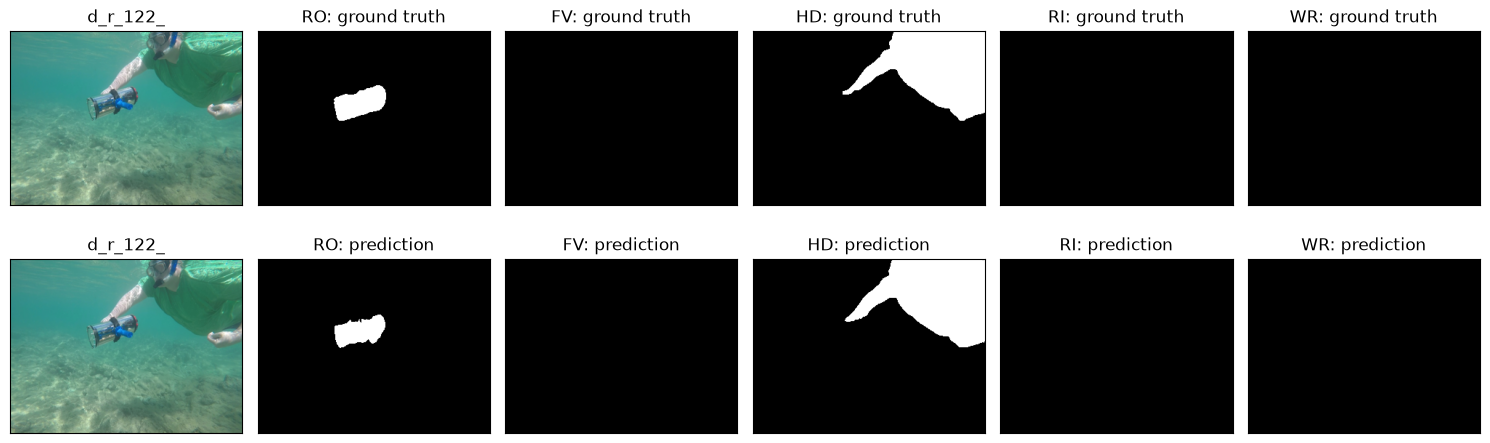

In [13]:
stem = selected_test_stems[0]
with Image.open(test_images[stem]) as source:
    image = source.convert('RGB').resize((WIDTH, HEIGHT), Image.Resampling.BICUBIC)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row in range(2):
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(stem)
for channel, symbol in enumerate(CLASSES, start=1):
    axes[0, channel].imshow(read_and_bin(ground_truth[symbol][stem], (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
    axes[0, channel].set_title(f'{symbol}: ground truth')
    axes[1, channel].imshow(read_and_bin(PREDICTION_DIR / symbol / f'{stem}.bmp', (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
    axes[1, channel].set_title(f'{symbol}: prediction')
for axis in axes.flat:
    axis.set_xticks([])
    axis.set_yticks([])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'prediction_example.png', dpi=140)
plt.show()

## Source attribution and license

Adapted from SUIM, Md Jahidul Islam (2020), revision
`59f7cb0d4d13289434ad6e3ab162ab7a5dcc5c84`; source-file hashes are recorded in this
notebook's `suim_sources` metadata and the project's `UPSTREAM_SUIM.md`.
Boundary evaluation also retains the upstream attribution to
[the DAVIS evaluation implementation](https://github.com/fperazzi/davis).

The upstream license is reproduced below for sharing this notebook:

```text
MIT License

Copyright (c) [2020] [Md Jahidul Islam]

SUIM-Net: Semantic Segmentation of Underwater Imagery: Dataset and Benchmark
Paper: https://arxiv.org/pdf/2004.01241.pdf
Original repository: https://github.com/xahidbuffon/SUIM-Net

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```

API references: [Keras weight saving](https://keras.io/api/models/model_saving_apis/weights_saving_and_loading/),
[Keras training](https://keras.io/api/models/model_training_apis/), and
[ImageDataGenerator parameters](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator).